# Data Preparation — AASE 2026/27
**Fase 3 CRISP-DM — Preparação de dados de internamento neonatal**

> ⚠️ Os datasets originais em `../dados_aase_202627/` são **intocáveis** — este notebook lê-os e escreve ficheiros novos em `03_data_preparation/`.

| Output | Fase | Descrição |
|---|---|---|
| `sinais_vitais_limpo.csv` | 3 | Registos com IDs normalizados (todos) |
| `patologias_limpo.csv` | 3 | Patologias com IDs normalizados |
| `dataset_final.csv` | 3 | Dataset agregado por episódio (features + targets) |
| `metadata.csv` | 3 | Mapeamento label → patologia + contagens |
| `dataset_regressao_24h.csv` | 3 | Preditores 24 h + alvo futuro (regressão) |

> Os ficheiros `train.csv`, `test.csv` e `normalisation_params.csv` são produzidos
> em `04_modeling/classificacao_patologia.ipynb` (Fase 4).

## 0. Imports e configuração

In [1]:
import csv
import math
import random
import statistics
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

%matplotlib inline

# paleta idêntica ao EDA
C = {
    "blue":   "#2a78d6",
    "orange": "#eb6834",
    "teal":   "#1baf7a",
    "yellow": "#eda100",
    "red":    "#d03b3b",
    "grey":   "#8996ae",
    "bg":     "#f4f7fc",
    "surf":   "#ffffff",
    "text":   "#0d1219",
    "text2":  "#4a5568",
}

plt.rcParams.update({
    "figure.facecolor":  C["bg"],
    "axes.facecolor":    C["surf"],
    "axes.edgecolor":    "#dce3f0",
    "axes.labelcolor":   C["text2"],
    "axes.grid":         True,
    "axes.axisbelow":    True,
    "grid.color":        "#e6eaf3",
    "grid.linewidth":    0.8,
    "xtick.color":       C["text2"],
    "ytick.color":       C["text2"],
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "font.family":       "sans-serif",
    "font.size":         10,
    "axes.titlesize":    12,
    "axes.titleweight":  "semibold",
    "axes.titlepad":     10,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "figure.dpi":        110,
})

PASTA   = "../dados_aase_202627"   # dados originais — só leitura
OUT_DIR = Path(".")
SEED    = 42
random.seed(SEED)
print("Pronto.")

Pronto.


## 1. Leitura dos dados originais (read-only)

In [2]:
def safe_float(v):
    try:
        return float(v)
    except (ValueError, TypeError):
        return None

def norm_ep(ep_id):
    """Normaliza IDs: remove espaços e converte para maiúsculas.
    Os dados originais têm inconsistências: ' EP011', 'EP 016', 'ep016'.
    Esta função resolve em memória sem alterar os ficheiros originais."""
    return ep_id.strip().replace(" ", "").upper()

MAPA_PAT = {
    "doenca das membranas hialinas":  "Doença das Membranas Hialinas",
    "doença das membranas hialinas":  "Doença das Membranas Hialinas",
    "dmh":                            "Doença das Membranas Hialinas",
    "icterícia neonatal":             "Icterícia Neonatal",
    "ictericia neonatal":             "Icterícia Neonatal",
    "anemia":                         "Anemia",
    "citomegalovírus":                "Citomegalovírus",
    "citomegalovirus":                "Citomegalovírus",
    "cmv":                            "Citomegalovírus",
    "displasia broncopulmonar":       "Displasia Broncopulmonar",
    "persistência do canal arterial": "Persistência do Canal Arterial",
    "refluxo gastroesofágico":        "Refluxo Gastroesofágico",
    "refluxo gastroesofagico":          "Refluxo Gastroesofágico",
    "sépsis":                         "Sépsis",
    "sepsis":                           "Sépsis",
    "lesão renal aguda":              "Lesão Renal Aguda",
    "retinopatia da prematuridade":   "Retinopatia da Prematuridade",
    "icterícia":                      "Icterícia Neonatal",
    "ictericia":                      "Icterícia Neonatal",
    "rge":                            "Refluxo Gastroesofágico",
}

def norm_pat(p):
    return MAPA_PAT.get(p.strip().lower(), p.strip().title())

# leitura — nunca se escreve nestes ficheiros
with open(f"{PASTA}/1_sinais_vitais_por_hora-1.csv", newline="", encoding="utf-8") as f:
    sv_raw = list(csv.DictReader(f))

with open(f"{PASTA}/3_patologias_por_dia-1.csv", newline="", encoding="utf-8") as f:
    pat_raw = list(csv.DictReader(f))

# normalizar IDs em memória (ficheiros originais não são alterados)
for r in sv_raw:
    r["episodio"] = norm_ep(r["episodio"])
for r in pat_raw:
    r["episodio"] = norm_ep(r["episodio"])

ep_ids_sv  = set(r["episodio"] for r in sv_raw)
ep_ids_pat = set(r["episodio"] for r in pat_raw)

print(f"Sinais vitais brutos: {len(sv_raw):,}")
print(f"Patologias brutas:    {len(pat_raw):,}")
print(f"IDs únicos SV:        {len(ep_ids_sv)}")
print(f"IDs únicos Pat:       {len(ep_ids_pat)}")
print(f"IDs em ambos:         {len(ep_ids_sv & ep_ids_pat)}")
so_sv  = ep_ids_sv  - ep_ids_pat
so_pat = ep_ids_pat - ep_ids_sv
if so_sv:  print(f"Só em SV:  {sorted(so_sv)}")
if so_pat: print(f"Só em Pat: {sorted(so_pat)}")

Sinais vitais brutos: 9,857
Patologias brutas:    696
IDs únicos SV:        47
IDs únicos Pat:       39
IDs em ambos:         39
Só em SV:  ['EP007', 'EP012', 'EP021', 'EP028', 'EP031', 'EP035', 'EP044', 'EP047']


## 1b. Auditoria de timestamps

Verificação sistemática dos formatos de data e detecção de timestamps duplicados,
**antes** de qualquer limpeza fisiológica.
Regra de parsing:
- `DD/MM/YYYY` → converte para `date(YYYY, MM, DD)`
- `YYYY-MM-DD` padrão
- `YYYY-MM-DD` com mês > 12 (ex.: `2024-13-02`) → lê como `YYYY-DD-MM`

In [3]:
from datetime import date as _date

def parse_data(d):
    d = d.strip()
    if '/' in d:
        parts = d.split('/')
        if len(parts) == 3:
            try:
                if len(parts[2]) == 4:           # DD/MM/YYYY
                    return _date(int(parts[2]), int(parts[1]), int(parts[0]))
            except (ValueError, TypeError):
                return None
    elif '-' in d:
        parts = d.split('-')
        if len(parts) == 3 and len(parts[0]) == 4:
            try:
                y, m, day = int(parts[0]), int(parts[1]), int(parts[2])
                if m > 12:           # YYYY-DD-MM → swap
                    m, day = day, m
                return _date(y, m, day)
            except (ValueError, TypeError):
                return None
    return None

# Aplicar a todos os registos brutos
audit_ts = []
for r in sv_raw:
    ep      = r["episodio"]
    d_pars  = parse_data(r["data"])
    h_val   = safe_float(r["hora"])
    h_ok    = h_val is not None and 0 <= h_val <= 23
    h_int   = int(h_val) if h_ok else None
    audit_ts.append({
        "episodio":    ep,
        "data_orig":   r["data"],
        "data_parsed": d_pars,
        "hora_orig":   r["hora"],
        "hora_num":    h_int,
        "ts_valido":   d_pars is not None and h_ok,
    })

n_data_inv = sum(1 for a in audit_ts if a["data_parsed"] is None)
n_hora_inv = sum(1 for a in audit_ts if a["hora_num"] is None)
n_ts_inv   = sum(1 for a in audit_ts if not a["ts_valido"])

# Contar timestamps duplicados
ts_grupos = defaultdict(list)
for i, a in enumerate(audit_ts):
    if a["ts_valido"]:
        ts_grupos[(a["episodio"], a["data_parsed"], a["hora_num"])].append(i)

dup_grupos = {k: v for k, v in ts_grupos.items() if len(v) > 1}
n_dup_reg  = sum(len(v) for v in dup_grupos.values())

print(f"Total registos brutos:        {len(sv_raw):,}")
print(f"Datas não interpretadas:      {n_data_inv}")
print(f"Horas inválidas (fora 0-23):  {n_hora_inv}")
print(f"Timestamps inválidos total:   {n_ts_inv}")
print(f"Grupos (ep,data,hora) dup.:   {len(dup_grupos)}")
print(f"Registos em grupos dup.:      {n_dup_reg}")

if dup_grupos:
    print("\nPrimeiros grupos duplicados:")
    for (ep, dt, h), idxs in list(dup_grupos.items())[:5]:
        print(f"  {ep} {dt} h={h:02d}  ({len(idxs)} registos)")

Total registos brutos:        9,857
Datas não interpretadas:      1
Horas inválidas (fora 0-23):  8
Timestamps inválidos total:   9
Grupos (ep,data,hora) dup.:   60
Registos em grupos dup.:      120

Primeiros grupos duplicados:
  EP003 2024-01-31 h=15  (2 registos)
  EP003 2024-02-04 h=05  (2 registos)
  EP001 2024-02-04 h=18  (2 registos)
  EP009 2024-02-05 h=05  (2 registos)
  EP008 2024-02-06 h=21  (2 registos)


## 1c. Resolução de timestamps duplicados

Para cada grupo `(episódio, data, hora)` com mais de um registo, consolida usando a
**mediana** de cada sinal. Decisão documentada: a mediana é robusta a leituras
espúrias pontuais e evita duplicar horas na janela temporal.

In [4]:
import statistics as _stats

def median_or_none(vals):
    valid = [v for v in vals if v is not None]
    return _stats.median(valid) if valid else None

sv_dedup = []
# registos com timestamp inválido passam direto (sem data/hora não entram na janela 24h)
for a in audit_ts:
    if not a["ts_valido"]:
        sv_dedup.append({**sv_raw[audit_ts.index(a)],
                         "_data_parsed": None, "_hora_num": None})

# registos com timestamp válido — consolidar por grupo
grupos_processados = set()
raw_index = {i: r for i, r in enumerate(sv_raw)}

for key, idxs in ts_grupos.items():
    ep, dt, h = key
    if len(idxs) == 1:
        r = sv_raw[idxs[0]]
        sv_dedup.append({**r, "_data_parsed": dt, "_hora_num": h})
    else:
        sats  = [safe_float(sv_raw[i]["sat_o2"])    for i in idxs]
        pulss = [safe_float(sv_raw[i]["puls_rate"]) for i in idxs]
        perfs = [safe_float(sv_raw[i]["perfusion"])  for i in idxs]
        rep   = sv_raw[idxs[0]]
        sv_dedup.append({
            "episodio":   rep["episodio"],
            "data":       rep["data"],
            "hora":       str(h),
            "sat_o2":     str(round(median_or_none(sats),  4)) if median_or_none(sats)  is not None else "",
            "puls_rate":  str(round(median_or_none(pulss), 4)) if median_or_none(pulss) is not None else "",
            "perfusion":  str(round(median_or_none(perfs), 4)) if median_or_none(perfs) is not None else "",
            "_data_parsed": dt,
            "_hora_num":    h,
        })

print(f"Registos brutos:          {len(sv_raw):,}")
print(f"Registos após dedup:      {len(sv_dedup):,}")
print(f"Redução por consolidação: {len(sv_raw) - len(sv_dedup)}")

Registos brutos:          9,857
Registos após dedup:      9,797
Redução por consolidação: 60


## 2. Limpeza — exclusão de registos inválidos

Estratégia: **exclusão** dos registos fora dos limiares fisiológicos.  
Justificação: valores fora dos intervalos (SpO₂ ∈ [50,100], FC ∈ [50,350], Perfusão ∈ [0,20]) representam erros de sensor, não estados clínicos. A imputação introduziria ruído artificial; a exclusão (2,5%) preserva a integridade clínica.

Válidos:   9,615  (97.5%)
Excluídos: 242   (2.5%)

  FC fora [50,350]: 91
  SpO₂ fora [50,100]: 74
  Perfusão fora [0,20]: 70
  Hora inválida: 8


/var/folders/36/8sjbwsxs0gd6823_mzrgxz2r0000gn/T/ipykernel_15988/1870156327.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_p, rotation=15, ha="right", fontsize=8.5)


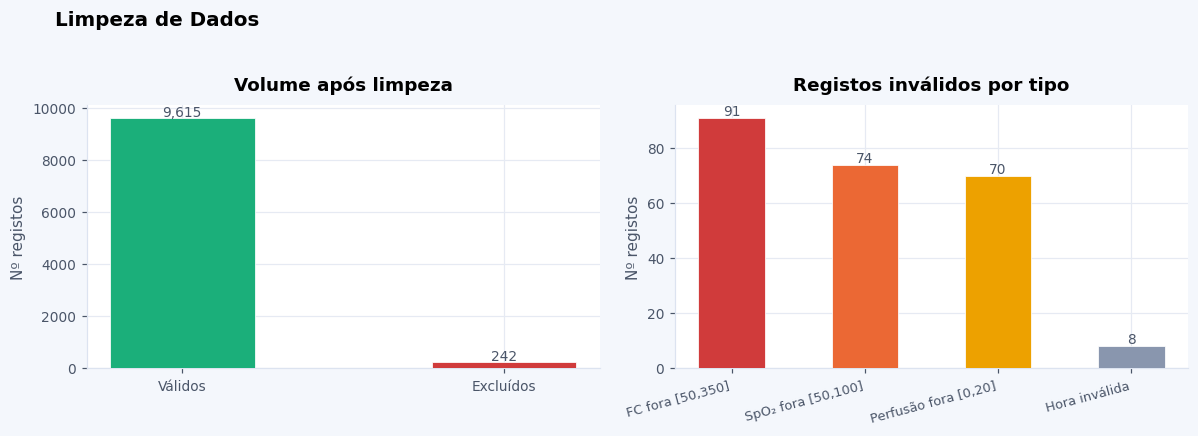

In [5]:
sv_clean, sv_inv = [], []
for r in sv_raw:
    sat  = safe_float(r["sat_o2"])
    puls = safe_float(r["puls_rate"])
    perf = safe_float(r["perfusion"])
    hora = safe_float(r["hora"])
    ok = (
        sat  is not None and 50 <= sat  <= 100 and
        puls is not None and 50 <= puls <= 350 and
        perf is not None and 0  <= perf <= 20  and
        hora is not None and 0  <= hora <= 23
    )
    (sv_clean if ok else sv_inv).append(r)

print(f"Válidos:   {len(sv_clean):,}  ({len(sv_clean)/len(sv_raw)*100:.1f}%)")
print(f"Excluídos: {len(sv_inv):,}   ({len(sv_inv)/len(sv_raw)*100:.1f}%)")

prob = Counter()
for r in sv_inv:
    sat  = safe_float(r["sat_o2"])
    puls = safe_float(r["puls_rate"])
    perf = safe_float(r["perfusion"])
    hora = safe_float(r["hora"])
    if sat  is None or not (50 <= sat  <= 100): prob["SpO₂ fora [50,100]"]   += 1
    if puls is None or not (50 <= puls <= 350): prob["FC fora [50,350]"]     += 1
    if perf is None or not (0  <= perf <= 20):  prob["Perfusão fora [0,20]"] += 1
    if hora is None or not (0  <= hora <= 23):  prob["Hora inválida"]        += 1

print()
for k, v in prob.most_common():
    print(f"  {k}: {v}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle("Limpeza de Dados", fontsize=13, fontweight="bold", x=0.05, ha="left")

ax = axes[0]
labels_q = ["Válidos", "Excluídos"]
vals_q   = [len(sv_clean), len(sv_inv)]
ax.bar(labels_q, vals_q, color=[C["teal"], C["red"]],
       width=0.45, zorder=3, edgecolor=C["surf"], linewidth=0.5)
ax.set_title("Volume após limpeza")
ax.set_ylabel("Nº registos")
for i, v in enumerate(vals_q):
    ax.text(i, v + 50, f"{v:,}", ha="center", fontsize=9, color=C["text2"])

ax = axes[1]
labels_p = list(prob.keys())
vals_p   = [prob[k] for k in labels_p]
cols_p   = [C["red"], C["orange"], C["yellow"], C["grey"]]
ax.bar(labels_p, vals_p, color=cols_p[:len(labels_p)],
       width=0.5, zorder=3, edgecolor=C["surf"], linewidth=0.5)
ax.set_title("Registos inválidos por tipo")
ax.set_ylabel("Nº registos")
ax.set_xticklabels(labels_p, rotation=15, ha="right", fontsize=8.5)
for i, v in enumerate(vals_p):
    ax.text(i, v + 1, str(v), ha="center", fontsize=9, color=C["text2"])

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 2b. Guardar ficheiros intermédios

Persiste os registos com IDs normalizados para que o notebook de validação seja autossuficiente.

In [6]:
sv_fields  = list(sv_raw[0].keys())
pat_fields = list(pat_raw[0].keys())

with open(OUT_DIR / "sinais_vitais_limpo.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=sv_fields)
    w.writeheader()
    w.writerows(sv_raw)

with open(OUT_DIR / "patologias_limpo.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=pat_fields)
    w.writeheader()
    w.writerows(pat_raw)

print(f"sinais_vitais_limpo.csv  {len(sv_raw):,} registos (IDs normalizados)")
print(f"patologias_limpo.csv     {len(pat_raw):,} registos (IDs normalizados)")

sinais_vitais_limpo.csv  9,857 registos (IDs normalizados)
patologias_limpo.csv     696 registos (IDs normalizados)


## 3. Agregação por episódio

Grão final: **1 linha = 1 episódio**.

| Feature | Descrição |
|---|---|
| `sat_o2_{mean,std,min,max}` | Estatísticas de SpO₂ |
| `puls_rate_{mean,std,min,max}` | Estatísticas de FC |
| `perfusion_{mean,std,min,max}` | Estatísticas de perfusão |
| `desat_count` | Nº de registos com SpO₂ < 90% |
| `desat_pct` | % de registos com dessaturação |
| `carga_dessaturacao` | Σ(90 − SpO₂) para SpO₂ < 90 (área de défice) |
| `duracao_dias` | Nº de dias distintos com sinais vitais registados |
| `n_registos` | Nº de registos válidos por episódio |

In [7]:
ep_sv = defaultdict(lambda: {"sat": [], "puls": [], "perf": [], "dias": set()})

for r in sv_clean:
    ep = r["episodio"]
    ep_sv[ep]["sat"].append(safe_float(r["sat_o2"]))
    ep_sv[ep]["puls"].append(safe_float(r["puls_rate"]))
    ep_sv[ep]["perf"].append(safe_float(r["perfusion"]))
    ep_sv[ep]["dias"].add(r["data"])

def ep_features(ep_id):
    d = ep_sv[ep_id]
    sat, puls, perf = d["sat"], d["puls"], d["perf"]
    n = len(sat)
    desat = [v for v in sat if v < 90]
    return {
        "episodio":           ep_id,
        "n_registos":         n,
        "sat_o2_mean":        round(statistics.mean(sat), 4),
        "sat_o2_std":         round(statistics.stdev(sat) if n > 1 else 0, 4),
        "sat_o2_min":         round(min(sat), 4),
        "sat_o2_max":         round(max(sat), 4),
        "puls_rate_mean":     round(statistics.mean(puls), 4),
        "puls_rate_std":      round(statistics.stdev(puls) if n > 1 else 0, 4),
        "puls_rate_min":      round(min(puls), 4),
        "puls_rate_max":      round(max(puls), 4),
        "perfusion_mean":     round(statistics.mean(perf), 4),
        "perfusion_std":      round(statistics.stdev(perf) if n > 1 else 0, 4),
        "perfusion_min":      round(min(perf), 4),
        "perfusion_max":      round(max(perf), 4),
        "desat_count":        len(desat),
        "desat_pct":          round(len(desat) / n * 100, 4),
        "carga_dessaturacao": round(sum(90 - v for v in desat), 4),
        "duracao_dias":       len(d["dias"]),
    }

eps_sorted = sorted(ep_sv.keys())
features   = [ep_features(ep) for ep in eps_sorted]

print(f"Episódios com sinais vitais: {len(features)}")
print(f"\nExemplo — {features[0]['episodio']}:")
for k, v in features[0].items():
    print(f"  {k:<24} {v}")

Episódios com sinais vitais: 47

Exemplo — EP001:
  episodio                 EP001
  n_registos               548
  sat_o2_mean              93.9073
  sat_o2_std               1.9901
  sat_o2_min               85.82
  sat_o2_max               99.79
  puls_rate_mean           158.6916
  puls_rate_std            6.5216
  puls_rate_min            137.43
  puls_rate_max            175.16
  perfusion_mean           1.1691
  perfusion_std            0.3305
  perfusion_min            0.49
  perfusion_max            2.59
  desat_count              22
  desat_pct                4.0146
  carga_dessaturacao       25.26
  duracao_dias             24


## 4. Targets

### 4a. Alvo de classificação — patologia predominante
Para cada episódio: a patologia com mais registos dia×episódio.  
Em empate usa-se a primeira por ordem alfabética (determinístico).

### 4b. Alvo de regressão
Dois candidatos (ambos incluídos; escolha final confirmada com docente):
- `duracao_dias` — dias distintos com sinais vitais registados
- `carga_dessaturacao` — Σ(90 − SpO₂) para SpO₂ < 90%

In [8]:
ep_pat_count = defaultdict(Counter)
for r in pat_raw:
    if r["patologia"].strip():
        ep_pat_count[r["episodio"]][norm_pat(r["patologia"])] += 1

def pat_predominante(ep_id):
    if ep_id not in ep_pat_count or not ep_pat_count[ep_id]:
        return None
    cnt = ep_pat_count[ep_id]
    max_n = max(cnt.values())
    return sorted(p for p, n in cnt.items() if n == max_n)[0]

sem_pat = []
for row in features:
    pp = pat_predominante(row["episodio"])
    row["pat_predominante"] = pp
    if pp is None:
        sem_pat.append(row["episodio"])

dist_pat = Counter(r["pat_predominante"] for r in features if r["pat_predominante"])

print(f"Com patologia: {sum(1 for r in features if r['pat_predominante'])}/{len(features)}")
if sem_pat:
    print(f"Sem patologia (serão excluídos do split): {sem_pat}")
print()
for p, n in dist_pat.most_common():
    print(f"  {n:3d}  {p}")

Com patologia: 39/47
Sem patologia (serão excluídos do split): ['EP007', 'EP012', 'EP021', 'EP028', 'EP031', 'EP035', 'EP044', 'EP047']

   24  Doença das Membranas Hialinas
    7  Icterícia Neonatal
    4  Citomegalovírus
    2  Anemia
    1  Displasia Broncopulmonar
    1  Persistência do Canal Arterial


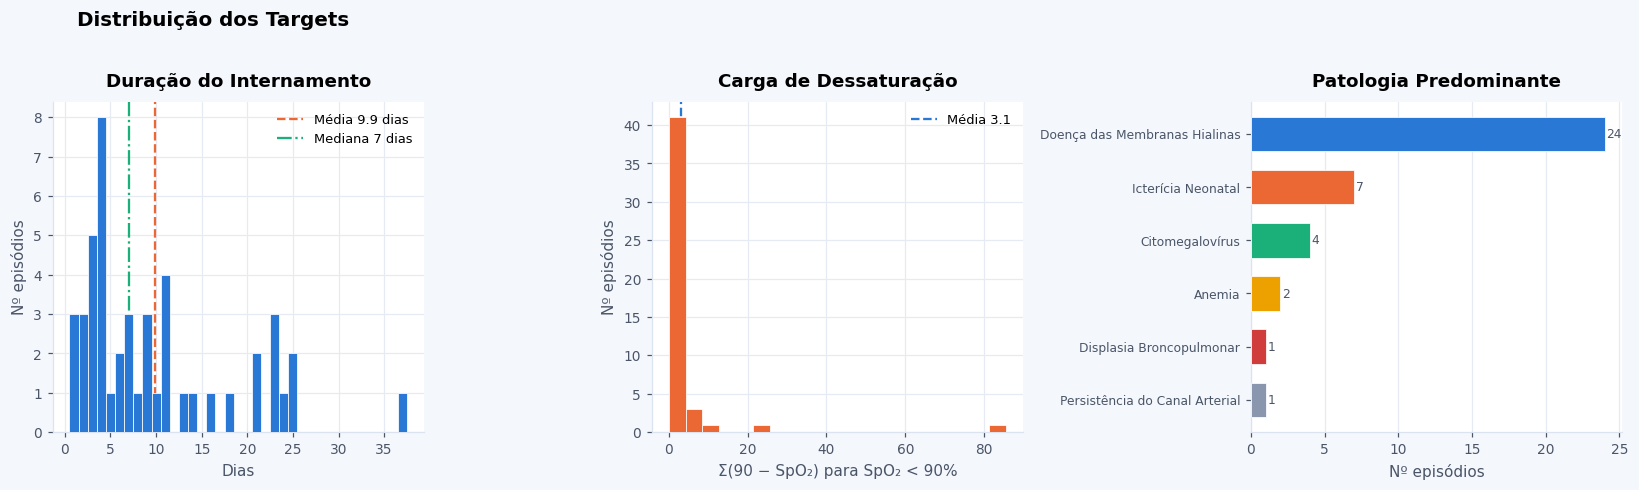

In [9]:
duracoes = [r["duracao_dias"]       for r in features]
cargas   = [r["carga_dessaturacao"] for r in features]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle("Distribuição dos Targets", fontsize=13, fontweight="bold",
             x=0.05, ha="left")

ax = axes[0]
ax.hist(duracoes, bins=range(1, max(duracoes) + 2), color=C["blue"],
        edgecolor=C["surf"], linewidth=0.5, zorder=3, align="left")
ax.axvline(statistics.mean(duracoes), color=C["orange"], lw=1.5, ls="--",
           label=f"Média {statistics.mean(duracoes):.1f} dias")
ax.axvline(statistics.median(duracoes), color=C["teal"], lw=1.5, ls="-.",
           label=f"Mediana {statistics.median(duracoes):.0f} dias")
ax.set_title("Duração do Internamento")
ax.set_xlabel("Dias")
ax.set_ylabel("Nº episódios")
ax.legend(fontsize=8.5, frameon=False)

ax = axes[1]
ax.hist(cargas, bins=20, color=C["orange"],
        edgecolor=C["surf"], linewidth=0.5, zorder=3)
ax.axvline(statistics.mean(cargas), color=C["blue"], lw=1.5, ls="--",
           label=f"Média {statistics.mean(cargas):.1f}")
ax.set_title("Carga de Dessaturação")
ax.set_xlabel("Σ(90 − SpO₂) para SpO₂ < 90%")
ax.set_ylabel("Nº episódios")
ax.legend(fontsize=8.5, frameon=False)

ax = axes[2]
pats_ord = [p for p, _ in dist_pat.most_common()]
counts_p = [dist_pat[p] for p in pats_ord]
cols_loop = [C["blue"], C["orange"], C["teal"], C["yellow"], C["red"], C["grey"]]
ax.barh(range(len(pats_ord)), counts_p,
        color=[cols_loop[i % len(cols_loop)] for i in range(len(pats_ord))],
        height=0.65, zorder=3, edgecolor=C["surf"], linewidth=0.5)
ax.set_yticks(range(len(pats_ord)))
ax.set_yticklabels(pats_ord, fontsize=8)
ax.invert_yaxis()
ax.set_title("Patologia Predominante")
ax.set_xlabel("Nº episódios")
ax.grid(axis="y", visible=False)
for i, v in enumerate(counts_p):
    ax.text(v + 0.1, i, str(v), va="center", fontsize=8, color=C["text2"])

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 5. Codificação — label encoding

### 5a. Label encoding
Atribui inteiro 0–N a cada patologia (ordem de frequência decrescente).
Episódios sem patologia recebem `pat_label = -1` e são mantidos no `dataset_final.csv`.

> ⚙️ A normalização Z-score e a divisão treino/teste são realizadas na
> **Fase 4** (`04_modeling/classificacao_patologia.ipynb`), onde os
> parâmetros são calculados exclusivamente no conjunto de treino.

In [10]:
pats_por_freq = [p for p, _ in dist_pat.most_common()]
pat_to_label  = {p: i for i, p in enumerate(pats_por_freq)}
label_to_pat  = {i: p for p, i in pat_to_label.items()}

print("Mapeamento patologia → label:")
for p, lbl in pat_to_label.items():
    print(f"  {lbl:2d}  {p}  (n={dist_pat[p]})")

for row in features:
    if row["pat_predominante"]:
        row["pat_label"] = pat_to_label[row["pat_predominante"]]
    else:
        row["pat_label"] = -1

FEATURE_COLS = [
    "sat_o2_mean",    "sat_o2_std",    "sat_o2_min",    "sat_o2_max",
    "puls_rate_mean", "puls_rate_std", "puls_rate_min", "puls_rate_max",
    "perfusion_mean", "perfusion_std", "perfusion_min", "perfusion_max",
    "desat_count",    "desat_pct",
]

print(f"\nFeatures numéricas: {len(FEATURE_COLS)}")
print("Label encoding concluído — normalização Z-score em 04_modeling/classificacao_patologia.ipynb")

Mapeamento patologia → label:
   0  Doença das Membranas Hialinas  (n=24)
   1  Icterícia Neonatal  (n=7)
   2  Citomegalovírus  (n=4)
   3  Anemia  (n=2)
   4  Displasia Broncopulmonar  (n=1)
   5  Persistência do Canal Arterial  (n=1)

Features numéricas: 14
Label encoding concluído — normalização Z-score em 04_modeling/classificacao_patologia.ipynb


## 7. Guardar outputs

| Ficheiro | Conteúdo |
|---|---|
| `dataset_final.csv` | Todos os 47 episódios com features + targets (sem normalização) |
| `metadata.csv` | Mapeamento label → patologia + contagens |

In [11]:
def write_csv(path, rows, fieldnames):
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=fieldnames, extrasaction="ignore")
        w.writeheader()
        w.writerows(rows)
    print(f"  {Path(path).name:<32}  {len(rows):>4} linhas")

BASE_COLS   = ["episodio", "n_registos"]
TARGET_COLS = ["duracao_dias", "carga_dessaturacao", "pat_predominante", "pat_label"]

print("Ficheiros criados (Fase 3):")
write_csv(OUT_DIR / "dataset_final.csv",
          features,
          BASE_COLS + FEATURE_COLS + TARGET_COLS)

write_csv(OUT_DIR / "metadata.csv",
          [{"pat_label": lbl, "pat_nome": label_to_pat[lbl],
            "n_episodios": dist_pat.get(label_to_pat[lbl], 0)}
           for lbl in sorted(label_to_pat)],
          ["pat_label", "pat_nome", "n_episodios"])

print("\nDatasets originais não foram alterados.")
print("\n→ train.csv, test.csv e normalisation_params.csv são gerados em")
print("  04_modeling/classificacao_patologia.ipynb")

Ficheiros criados (Fase 3):
  dataset_final.csv                   47 linhas
  metadata.csv                         6 linhas

Datasets originais não foram alterados.

→ train.csv, test.csv e normalisation_params.csv são gerados em
  04_modeling/classificacao_patologia.ipynb


## 7b. Dataset de regressão — janela 24h

Cria `dataset_regressao_24h.csv` para modelação preditiva antecipada:
- **Preditores**: estatísticas das primeiras 24 horas (desde o 1.º registo do episódio)
- **Alvo** (`carga_dessaturacao_futura`): Σ(90 − SpO₂) para SpO₂ < 90%, **após** as primeiras 24 h

### Critérios de elegibilidade
- Mínimo **5 registos SpO₂ válidos** na janela inicial (primeiras 24h)
- Mínimo **3 registos SpO₂ válidos** na janela futura
- Motivação: EP018 e EP042 tinham apenas 1 registo inicial — insuficiente para caracterizar o estado fisiológico

SpO₂ inválido fisiologicamente → excluído do cálculo de dessaturação mesmo com outras variáveis válidas.

In [12]:
from datetime import datetime as _dt, timedelta as _td

# ---------- Step 1: construir lista limpa com timestamps reais ----------
sv_ts = []
for r in sv_dedup:
    d_p = r.get("_data_parsed")
    h_p = r.get("_hora_num")
    if d_p is None or h_p is None:
        continue
    sat  = safe_float(r["sat_o2"])
    puls = safe_float(r["puls_rate"])
    perf = safe_float(r["perfusion"])
    spo2_ok = sat  is not None and 50 <= sat  <= 100
    all_ok  = (spo2_ok and
               puls is not None and 50 <= puls <= 350 and
               perf is not None and 0  <= perf <= 20)
    sv_ts.append({
        "episodio":   r["episodio"],
        "data_date":  d_p,
        "hora_num":   h_p,
        "sat_o2":     sat,
        "puls_rate":  puls,
        "perfusion":  perf,
        "spo2_ok":    spo2_ok,
        "all_ok":     all_ok,
    })

# ---------- Step 2: ordenar por episódio e timestamp ----------
sv_ts.sort(key=lambda r: (r["episodio"], r["data_date"], r["hora_num"]))

# ---------- Step 3: agrupar por episódio ----------
ep_records = defaultdict(list)
for r in sv_ts:
    ep_records[r["episodio"]].append(r)

# ---------- Step 4: calcular features 24h e alvo futuro ----------
JANELA_H = 24  # horas da janela de observação

def stats_spo2(records):
    # SpO2 stats; only records with spo2_ok=True
    vals = [r["sat_o2"] for r in records if r["spo2_ok"]]
    if not vals:
        return None
    return {
        "sat_o2_mean": round(_stats.mean(vals), 4),
        "sat_o2_std":  round(_stats.stdev(vals) if len(vals) > 1 else 0, 4),
        "sat_o2_min":  round(min(vals), 4),
        "sat_o2_max":  round(max(vals), 4),
        "desat_count": sum(1 for v in vals if v < 90),
        "desat_pct":   round(sum(1 for v in vals if v < 90) / len(vals) * 100, 4),
        "carga_desat_janela": round(sum(90 - v for v in vals if v < 90), 4),
        "n_spo2_validos": len(vals),
    }

def stats_all(records):
    # FC and perfusion stats; only records with all_ok=True
    puls = [r["puls_rate"] for r in records if r["all_ok"]]
    perf = [r["perfusion"] for r in records if r["all_ok"]]
    n    = len(puls)
    if not puls:
        return None
    return {
        "puls_rate_mean": round(_stats.mean(puls), 4),
        "puls_rate_std":  round(_stats.stdev(puls) if n > 1 else 0, 4),
        "puls_rate_min":  round(min(puls), 4),
        "puls_rate_max":  round(max(puls), 4),
        "perfusion_mean": round(_stats.mean(perf), 4),
        "perfusion_std":  round(_stats.stdev(perf) if n > 1 else 0, 4),
        "perfusion_min":  round(min(perf), 4),
        "perfusion_max":  round(max(perf), 4),
        "n_all_validos":  n,
    }

regressao_rows = []
cobertura_log  = []

for ep, records in sorted(ep_records.items()):
    # t_start = primeiro timestamp válido do episódio
    t_start_date = records[0]["data_date"]
    t_start_hora = records[0]["hora_num"]

    janela_rec  = []
    futuro_rec  = []

    for r in records:
        # diferença em horas (dias × 24 + horas)
        delta_dias = (r["data_date"] - t_start_date).days
        delta_h    = delta_dias * 24 + (r["hora_num"] - t_start_hora)
        if delta_h < JANELA_H:
            janela_rec.append(r)
        else:
            futuro_rec.append(r)

    n_janela = sum(1 for r in janela_rec if r["spo2_ok"])
    n_futuro = sum(1 for r in futuro_rec if r["spo2_ok"])

    cobertura_log.append({
        "episodio": ep,
        "n_janela_spo2": n_janela,
        "n_futuro_spo2": n_futuro,
        "elegivel": n_janela >= 5 and n_futuro >= 3,
    })

    if n_janela < 5 or n_futuro < 3:
        continue  # episódio inelegível

    # calcular carga futura (alvo)
    carga_futura = round(
        sum(90 - r["sat_o2"] for r in futuro_rec if r["spo2_ok"] and r["sat_o2"] < 90),
        4
    )

    # features da janela
    st_spo2 = stats_spo2(janela_rec)
    st_all  = stats_all(janela_rec)
    if st_spo2 is None:
        continue

    row = {"episodio": ep}
    row.update(st_spo2)
    if st_all:
        row.update(st_all)
    else:
        for k in ["puls_rate_mean","puls_rate_std","puls_rate_min","puls_rate_max",
                  "perfusion_mean","perfusion_std","perfusion_min","perfusion_max","n_all_validos"]:
            row[k] = None
    row["n_registos_janela"] = len(janela_rec)
    row["n_registos_futuro"] = len(futuro_rec)
    row["carga_dessaturacao_futura"] = carga_futura

    regressao_rows.append(row)

print(f"Episódios com registos temporais: {len(ep_records)}")
print(f"Episódios elegíveis:              {len(regressao_rows)}")
print()
print(f"{'Ep':<8} {'Janela SpO₂':>12} {'Futuro SpO₂':>12} {'Elegível':>9}")
print("-" * 46)
for c in cobertura_log:
    flag = "✅" if c["elegivel"] else "❌"
    print(f"  {c['episodio']:<6} {c['n_janela_spo2']:>12} {c['n_futuro_spo2']:>12} {flag:>9}")

Episódios com registos temporais: 47
Episódios elegíveis:              43

Ep        Janela SpO₂  Futuro SpO₂  Elegível
----------------------------------------------
  EP001            24          531         ✅
  EP002            23           33         ✅
  EP003            24          103         ✅
  EP004            17          480         ✅
  EP005            24           62         ✅
  EP006            24          178         ✅
  EP007            23           37         ✅
  EP008            23          286         ✅
  EP009            24           34         ✅
  EP010            18            0         ❌
  EP011            23          160         ✅
  EP012            24          170         ✅
  EP013            24          147         ✅
  EP014            24           90         ✅
  EP015            23          467         ✅
  EP016            24          457         ✅
  EP017            23          469         ✅
  EP018             1          482         ✅
  EP019            24  

In [13]:
# Guardar dataset_regressao_24h.csv
if regressao_rows:
    REGRESSAO_COLS = [
        "episodio",
        "n_registos_janela", "n_spo2_validos", "n_all_validos",
        "sat_o2_mean", "sat_o2_std", "sat_o2_min", "sat_o2_max",
        "puls_rate_mean", "puls_rate_std", "puls_rate_min", "puls_rate_max",
        "perfusion_mean", "perfusion_std", "perfusion_min", "perfusion_max",
        "desat_count", "desat_pct", "carga_desat_janela",
        "n_registos_futuro",
        "carga_dessaturacao_futura",
    ]
    path_reg = OUT_DIR / "dataset_regressao_24h.csv"
    with open(path_reg, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=REGRESSAO_COLS, extrasaction="ignore")
        w.writeheader()
        w.writerows(regressao_rows)
    print(f"dataset_regressao_24h.csv  →  {len(regressao_rows)} episódios, {len(REGRESSAO_COLS)} colunas")

    # mini-análise do alvo
    cargas_fut = [r["carga_dessaturacao_futura"] for r in regressao_rows]
    print(f"\nAlvo — carga_dessaturacao_futura:")
    print(f"  mín={min(cargas_fut):.2f}  máx={max(cargas_fut):.2f}  "
          f"média={_stats.mean(cargas_fut):.2f}  mediana={_stats.median(cargas_fut):.2f}")
    zeros = sum(1 for v in cargas_fut if v == 0)
    print(f"  episódios com carga=0 (sem dessaturação futura): {zeros}/{len(cargas_fut)}")
else:
    print("⚠ Nenhum episódio elegível — verificar cobertura temporal.")

dataset_regressao_24h.csv  →  43 episódios, 21 colunas

Alvo — carga_dessaturacao_futura:
  mín=0.00  máx=85.57  média=3.21  mediana=0.00
  episódios com carga=0 (sem dessaturação futura): 30/43


## 8. Verificação final

In [14]:
import os

# Fase 3 — ficheiros produzidos por este notebook
outputs_f3 = [
    "dataset_final.csv",
    "dataset_regressao_24h.csv",
    "metadata.csv",
    "sinais_vitais_limpo.csv",
    "patologias_limpo.csv",
]

print("Ficheiros Fase 3 em 03_data_preparation/:")
print(f"  {'Ficheiro':<34}  {'Linhas':>6}  {'Colunas':>7}  {'Tamanho':>8}")
print("-" * 65)
for fname in outputs_f3:
    path = OUT_DIR / fname
    with open(path, newline="", encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    size_kb = os.path.getsize(path) / 1024
    print(f"  {fname:<34}  {len(rows):>6}  {len(rows[0]) if rows else 0:>7}  {size_kb:>6.1f} KB")

print()
print("Datasets originais (verificação de integridade):")
for fname, esperado in [
    ("1_sinais_vitais_por_hora-1.csv", 9857),
    ("3_patologias_por_dia-1.csv",     696),
]:
    path = f"{PASTA}/{fname}"
    with open(path, newline="", encoding="utf-8") as f:
        n = sum(1 for _ in csv.reader(f)) - 1
    status = "✅ intacto" if n == esperado else f"⚠ ESPERADO {esperado}, encontrado {n}"
    print(f"  {fname}  ({n:,} registos) {status}")

print()
print("Resumo (Fase 3):")
print(f"  Episódios total:           {len(features)}")
print(f"  Com patologia definida:    {sum(1 for r in features if r['pat_predominante'])}")
print(f"  Features numéricas:        {len(FEATURE_COLS)}")
print(f"  Classes de patologia:      {len(pat_to_label)}")
print(f"  Registos SV excluídos:     {len(sv_inv)} (2.5%)")
print(f"  Episódios reg. elegíveis:  {len(regressao_rows)} / {len(features)}")
print()
print("-> Próximo passo: 04_modeling/classificacao_patologia.ipynb (Fase 4)")

Ficheiros Fase 3 em 03_data_preparation/:
  Ficheiro                            Linhas  Colunas   Tamanho
-----------------------------------------------------------------
  dataset_final.csv                       47       20     6.1 KB
  dataset_regressao_24h.csv               43       21     4.9 KB
  metadata.csv                             6        3     0.2 KB
  sinais_vitais_limpo.csv               9857        6   367.2 KB
  patologias_limpo.csv                   696        3    28.1 KB

Datasets originais (verificação de integridade):
  1_sinais_vitais_por_hora-1.csv  (9,857 registos) ✅ intacto
  3_patologias_por_dia-1.csv  (696 registos) ✅ intacto

Resumo (Fase 3):
  Episódios total:           47
  Com patologia definida:    39
  Features numéricas:        14
  Classes de patologia:      6
  Registos SV excluídos:     242 (2.5%)
  Episódios reg. elegíveis:  43 / 47

-> Próximo passo: 04_modeling/classificacao_patologia.ipynb (Fase 4)
